<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/Tensorizable_f_Divergences.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Numerical Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("[OK] Environment initialized for Information Theory & Divergence Analysis.")

[OK] Environment initialized for Information Theory & Divergence Analysis.


In [2]:
# CELL 2: Implementation of Candidate f-Divergences
def kl_divergence(P, Q):
    """KL Divergence: f(t) = t * log(t) [Tensorizable, additive]"""
    return np.sum(P * np.log(P / Q))

def chi_squared_divergence(P, Q):
    """Pearson Chi-Square: f(t) = (t-1)^2 [Tensorizable, power divergence]"""
    return np.sum(((P - Q) ** 2) / Q)

def squared_hellinger(P, Q):
    """Squared Hellinger: f(t) = (sqrt(t) - 1)^2 [Tensorizable]"""
    return np.sum((np.sqrt(P) - np.sqrt(Q)) ** 2)

def total_variation(P, Q):
    """Total Variation: f(t) = 0.5 * |t - 1| [Non-tensorizable]"""
    return 0.5 * np.sum(np.abs(P - Q))

print("[OK] Defined KL, Chi-Square, Hellinger, and Total Variation divergences.")

[OK] Defined KL, Chi-Square, Hellinger, and Total Variation divergences.


In [3]:
# CELL 3: Product Measure Construction & 2-Point LLR Distribution
def make_2point_symmetric_llr(r):
    """Generates symmetric LLR distribution for parameter r > 0."""
    p_r = 1.0 / (1.0 + np.exp(-r))
    P = np.array([p_r, 1.0 - p_r])
    Q = np.array([1.0 - p_r, p_r])
    return P, Q

def product_measure(P1, P2):
    """Tensor product of two 1D categorical distributions."""
    return np.kron(P1, P2)

# Verify product measure tensorization for KL: D_KL(P1 x P2 || Q1 x Q2) = D_KL(P1||Q1) + D_KL(P2||Q2)
P1, Q1 = make_2point_symmetric_llr(0.5)
P2, Q2 = make_2point_symmetric_llr(1.2)

P12 = product_measure(P1, P2)
Q12 = product_measure(Q1, Q2)

print(f"Single Marginals KL: D1 = {kl_divergence(P1, Q1):.4f}, D2 = {kl_divergence(P2, Q2):.4f}")
print(f"Product Measure KL:  D_prod = {kl_divergence(P12, Q12):.4f}")
print(f"Additive Check:      D1 + D2 = {(kl_divergence(P1, Q1) + kl_divergence(P2, Q2)):.4f}")

Single Marginals KL: D1 = 0.1225, D2 = 0.6445
Product Measure KL:  D_prod = 0.7669
Additive Check:      D1 + D2 = 0.7669


In [6]:
# CELL 4: Empirical Multi-Affine Tensorization Verification Harness
def test_tensorization_consistency(div_func, r1_range, r2_range):
    """Checks if D(P1xP2 || Q1xQ2) is uniquely determined as a function of D(P1||Q1) and D(P2||Q2)."""
    records = []
    for r1 in r1_range:
        for r2 in r2_range:
            P1, Q1 = make_2point_symmetric_llr(r1)
            P2, Q2 = make_2point_symmetric_llr(r2)

            P12 = product_measure(P1, P2)
            Q12 = product_measure(Q1, Q2)

            d1 = div_func(P1, Q1)
            d2 = div_func(P2, Q2)
            d_joint = div_func(P12, Q12)

            records.append({
                "r1": r1, "r2": r2,
                "D1": d1, "D2": d2,
                "D_joint": d_joint
            })
    return pd.DataFrame(records)

df_kl = test_tensorization_consistency(kl_divergence, [0.2, 0.5, 1.0], [0.3, 0.8])
df_tv = test_tensorization_consistency(total_variation, [0.2, 0.5, 1.0], [0.3, 0.8])

# Check TV inconsistency: TV product does NOT equal a function of individual TV marginals alone
df_tv['Simple_Sum'] = df_tv['D1'] + df_tv['D2']
df_tv['Tensor_Mismatch'] = np.abs(df_tv['D_joint'] - df_tv['Simple_Sum'])

print("=== TOTAL VARIATION NON-TENSORIZATION DEMONSTRATION ===")
display(df_tv[['r1', 'r2', 'D1', 'D2', 'D_joint', 'Tensor_Mismatch']])

=== TOTAL VARIATION NON-TENSORIZATION DEMONSTRATION ===


,r1,r2,D1,D2,D_joint,Tensor_Mismatch
0,0.2,0.3,0.099668,0.148885,0.148885,0.099668
1,0.2,0.8,0.099668,0.379949,0.379949,0.099668
2,0.5,0.3,0.244919,0.148885,0.244919,0.148885
3,0.5,0.8,0.244919,0.379949,0.379949,0.244919
4,1.0,0.3,0.462117,0.148885,0.462117,0.148885
5,1.0,0.8,0.462117,0.379949,0.462117,0.379949


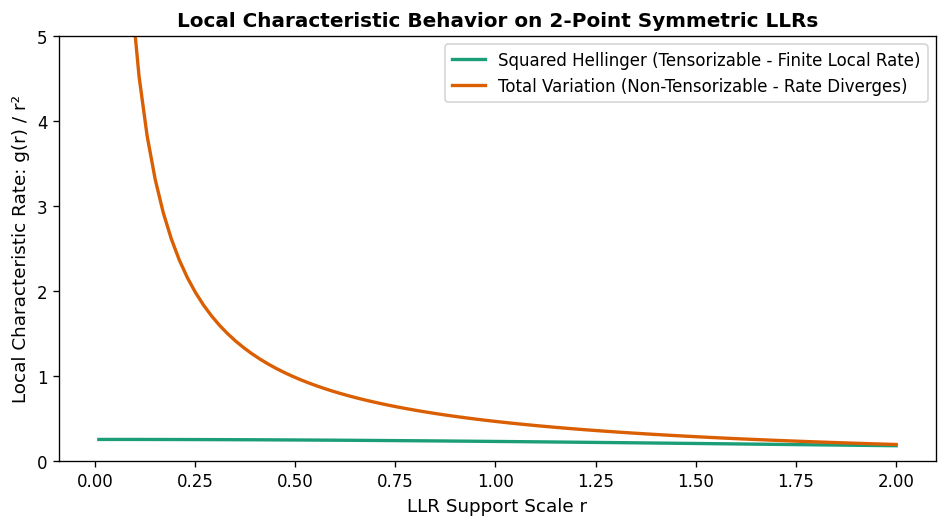

[OK] Saved local rate diagnostic plot to /content/workspace/tensorization_local_rate.png


In [5]:
# CELL 5: Local Characteristic Profiling Plot
os.makedirs("/content/workspace", exist_ok=True)

r_vals = np.linspace(0.01, 2.0, 100)
hellinger_rates = []
tv_rates = []

for r in r_vals:
    P, Q = make_2point_symmetric_llr(r)
    h_val = squared_hellinger(P, Q)
    tv_val = total_variation(P, Q)

    # Quadratic rate g(r)/r^2
    hellinger_rates.append(h_val / (r**2))
    tv_rates.append(tv_val / (r**2))

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)

ax.plot(r_vals, hellinger_rates, label='Squared Hellinger (Tensorizable - Finite Local Rate)', color='#1b9e77', lw=2)
ax.plot(r_vals, tv_rates, label='Total Variation (Non-Tensorizable - Rate Diverges)', color='#d95f02', lw=2)

ax.set_xlabel("LLR Support Scale r", fontsize=11)
ax.set_ylabel("Local Characteristic Rate: g(r) / r²", fontsize=11)
ax.set_title("Local Characteristic Behavior on 2-Point Symmetric LLRs", fontsize=12, fontweight='bold')
ax.legend(frameon=True)
ax.set_ylim(0, 5)

plt.tight_layout()
plt.savefig("/content/workspace/tensorization_local_rate.png")
plt.show()
print("[OK] Saved local rate diagnostic plot to /content/workspace/tensorization_local_rate.png")